# Lab notebook: AF-ΔΔG data pipeline and first result

**Thanh Ly** · PHYS 7440 GenAI in Physics Research · Assignment 9 (Week 9)

**Project question.** Does the AlphaFold structure of the wild-type protein tell me anything reliable about a missense variant? Quantitatively: can features of the AlphaFold DB model at the mutated residue (pLDDT, burial, AlphaMissense) predict the folding free-energy change ΔΔG of the variant better than my Week 8 sequence-only baseline (PhysChem-Ridge, RMSE = 1.54 kcal/mol on S669)?

**What this notebook records**

1. The provenance of the data, read from `provenance_ly.json` (written by `data_pipeline_ly.py`).
2. The **raw output of real API calls** (AlphaFold DB, AlphaMissense, PDBe SIFTS), exactly as the pipeline received them, from its SQLite cache.
3. The **normalised version** of the same records in my internal schema.
4. Physical sanity checks on the normalised data (training set only, so the test set stays unseen until it is scored).
5. The **first analysis result**: the AlphaFold-informed model AF-ΔΔG, trained on S2648, scored once on S669 and **compared with the Week 8 baseline** variant by variant (plot in section 5d).

**How to run.** First run the pipeline (`python data_pipeline_ly.py`, about 5–10 minutes the first time, seconds afterwards). Then run this notebook from the project folder (*Run All*, or `jupyter nbconvert --to notebook --execute --inplace lab_notebook_ly.ipynb`). The notebook itself needs no network access: it reads only the pipeline outputs and the cache.

**Software environment.** Python ≥ 3.10 (this notebook was run with Python 3.14) and the packages in `requirements.txt`. `bash run_all.sh` installs them automatically into a virtual environment `.venv`; by hand:

```bash
python3 -m venv .venv && source .venv/bin/activate
python -m pip install -r requirements.txt
```

| package | required | used for |
|---|---|---|
| `httpx` | ≥ 0.27, < 1 | HTTP client of the pipeline (same library as the Assignment 7 MCP server) |
| `tenacity` | ≥ 8.2 | retries with exponential backoff (failure mode a) |
| `numpy` | ≥ 1.24 | numerics, contact numbers |
| `pandas` | ≥ 2.0 | tables, normalisation |
| `pyarrow` | ≥ 14 | Parquet output of the normalised table |
| `scikit-learn` | ≥ 1.3 | Week 8 baseline (ridge) and AF-ΔΔG (gradient boosting) |
| `matplotlib` | ≥ 3.7 | figures |
| `pint` | ≥ 0.23 | units in `eval_harness.py` (Meeting 1 harness) |
| `pytest` | ≥ 8 | offline tests in `tests/` |
| `nbconvert`, `ipykernel` | ≥ 7, ≥ 6 | running this notebook from the command line |

The exact versions used for this run are printed by the first code cell below; the pipeline's own versions are recorded in `provenance_ly.json → pipeline.packages`.

**Conventions** (identical to Assignment 8): ΔΔG = ΔG<sub>unfold</sub>(mutant) − ΔG<sub>unfold</sub>(wild type) in kcal/mol, so **ΔΔG < 0 means destabilising**. Residues are numbered in UniProt coordinates. Missing values are stored as documented sentinels (−1 / `MISSING`) and turned into NaN with `dp.sentinels_to_nan()` before any calculation.

In [1]:
import json, platform, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import Markdown, display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import PredefinedSplit, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

HERE = Path.cwd()
assert (HERE / "data_pipeline_ly.py").exists(), "Start Jupyter in the 'Assignment 9' folder."
sys.path.insert(0, str(HERE))
import data_pipeline_ly as dp   # this assignment: ingestion, normalisation, cache, provenance
import features_ly as F         # Week 8: sequence-only substitution descriptors
import scoring_ly as S          # Week 8: RMSE, protein-clustered bootstrap, success rule
import eval_harness as H        # Week 8 Meeting 1 harness: per-variant scoring in physical units

PATHS = dp.Paths(HERE)
RESULTS = HERE / "results"
RESULTS.mkdir(exist_ok=True)
SEED = 7440
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)

assert PATHS.parquet.exists() and PATHS.provenance.exists(), "Run `python data_pipeline_ly.py` first."
prov = json.loads(PATHS.provenance.read_text(encoding="utf-8"))
import importlib.metadata as _md
_pkgs = ["httpx", "tenacity", "numpy", "pandas", "pyarrow", "scikit-learn", "matplotlib", "pint", "pytest", "nbconvert", "ipykernel"]
def _ver(p):
    try:
        return _md.version(p)
    except _md.PackageNotFoundError:
        return "not installed"
print(f"software environment: Python {platform.python_version()} on {platform.system()} {platform.machine()}")
print(pd.DataFrame({"package": _pkgs, "installed version": [_ver(p) for p in _pkgs]}).to_string(index=False))
print("pipeline run used:", ", ".join(f"{k} {v}" for k, v in prov["pipeline"]["packages"].items()))
print(f"pipeline run: {prov['pipeline']['run_started_utc']} -> {prov['pipeline']['run_finished_utc']} "
      f"({prov['pipeline']['command']})")
print("\nIntegrity check of the pipeline outputs against provenance_ly.json:")
assert dp.verify(HERE), "outputs do not match provenance_ly.json; re-run the pipeline"
failed = {d["name"]: d["failed_after_retries"] for d in prov["datasets"] if d.get("failed_after_retries")}
if failed:
    print("\nWARNING: some requests failed after all retries in this pipeline run:", failed,
          "\n         their fields are sentinels; re-run `python data_pipeline_ly.py` to fill them in.")
if prov["coverage"]["S669"]["with_alphafold_plddt"] == 0:
    raise RuntimeError("The pipeline run has no AlphaFold features at all (AlphaFold DB was unreachable). "
                       "Re-run `python data_pipeline_ly.py` when the APIs are reachable, then this notebook.")


software environment: Python 3.14.6 on Linux x86_64
     package installed version
       httpx            0.28.1
    tenacity             9.2.1
       numpy             2.5.5
      pandas             3.1.1
     pyarrow            26.0.1
scikit-learn             1.9.1
  matplotlib            3.11.2
        pint            0.26.2
      pytest             9.2.0
   nbconvert            7.17.2
   ipykernel             7.4.0
pipeline run used: python 3.14.10, httpx 0.28.1, tenacity 9.2.1, numpy 2.5.5, pandas 3.1.1, pyarrow 26.0.1
pipeline run: 2026-11-17T04:00:13+00:00 -> 2026-11-17T04:13:06+00:00 (python data_pipeline_ly.py --fresh)

Integrity check of the pipeline outputs against provenance_ly.json:
variants content SHA-256: 19494dbf4f8aa86ff43a90e6e016296c1c86ea41502199ccc6a3f827c61db448 -> OK
S669 raw file SHA-256: OK
S2648 raw file SHA-256: OK
schema columns: OK


## 1. Provenance at a glance

One row per data source. Files are pinned to a Git commit and a SHA-256 digest; API sources are fingerprinted by the SHA-256 over all their responses (`responses_sha256`) and dated by their first and last access. The full record, including the transformations applied to each source and the AlphaFold model version of every protein, is in `provenance_ly.json`.

In [2]:
def _version(d):
    return d.get("commit_pinned_in_url", "")[:12] + " (commit)" if d["type"] == "file" else d.get("version", "")

overview = pd.DataFrame([{
    "source": d["name"], "type": d["type"], "role": d["role"],
    "URL / endpoint": d.get("source_url") or d.get("endpoint"),
    "accessed (UTC)": d.get("access_timestamp_utc") or (
        f"{d.get('first_access_utc')} … {d.get('last_access_utc')}" if d.get("first_access_utc") else "not used"),
    "version": _version(d),
    "requests": d.get("requests", 1), "from cache": d.get("served_from_cache"),
    "failed after retries": d.get("failed_after_retries", 0),
} for d in prov["datasets"]])
display(overview)
print("content SHA-256 of the normalised table:", prov["outputs"]["variants"]["content_sha256"])
print("reproducibility:", {k: v for k, v in prov["reproducibility"].items() if k != "how_to_check"})


,source,type,role,URL / endpoint,accessed (UTC),version,requests,from cache,failed after retries
0,S669,file,test,https://raw.githubusercontent.com/compbiomed-unito/JanusDDG/7ef53fde72c9b9b715b0a9f2f8...,2026-11-17T04:00:13+00:00,7ef53fde72c9 (commit),1,False,0
1,S2648,file,train,https://raw.githubusercontent.com/protddg-bench/protddg-bench.github.io/72a5f300ca0f50...,2026-11-17T04:00:14+00:00,72a5f300ca0f (commit),1,False,0
2,PDBe SIFTS mappings,API,identifier normalisation of S2648 (PDB chain -> UniProt accession and numbering),https://www.ebi.ac.uk/pdbe/api/mappings/uniprot/{pdb_id} (fallback: https://www.ebi.ac...,2026-11-17T04:00:15+00:00 … 2026-11-17T04:00:49+00:00,SIFTS through the live PDBe API (no release number exposed); fingerprinted by response...,134,0,0
3,AlphaFold DB prediction API,API,model metadata and reference UniProt sequence,https://alphafold.ebi.ac.uk/api/prediction/{accession},2026-11-17T04:00:49+00:00 … 2026-11-17T04:01:45+00:00,"AlphaFold DB; model versions seen: 1, 6; files pinned to v6",209,0,0
4,AlphaFold DB confidence (pLDDT) files,API,per-residue model confidence,https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-confidence_v6.json,2026-11-17T04:01:45+00:00 … 2026-11-17T04:13:00+00:00,AlphaFold DB model v6,182,0,0
5,AlphaFold DB model coordinates (PDB),API,burial feature,https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-model_v6.pdb,2026-11-17T04:01:46+00:00 … 2026-11-17T04:13:01+00:00,AlphaFold DB model v6,182,0,0
6,AlphaMissense tables (AlphaFold DB),API,variant-effect prior (human proteins only),https://alphafold.ebi.ac.uk/files/AF-{accession}-F1-aa-substitutions.csv,2026-11-17T04:01:49+00:00 … 2026-11-17T04:13:04+00:00,"AlphaMissense (Cheng et al. 2023, Science 381, eadg7492) as served by AlphaFold DB; no...",57,0,0
7,UniProt REST (FASTA),API,fallback reference sequence when AlphaFold DB has no model,https://rest.uniprot.org/uniprotkb/{accession}.fasta,2026-11-17T04:00:56+00:00 … 2026-11-17T04:01:43+00:00,UniProtKB release current at the access time,13,0,0


content SHA-256 of the normalised table: 19494dbf4f8aa86ff43a90e6e016296c1c86ea41502199ccc6a3f827c61db448
reproducibility: {'previous_content_sha256': '19494dbf4f8aa86ff43a90e6e016296c1c86ea41502199ccc6a3f827c61db448', 'identical_to_previous': True, 'differences_from_previous_table': {'rows_only_in_previous': 0, 'rows_only_in_new': 0, 'changed_values_by_column': {}}}


## 2. Raw output of real API calls

The pipeline caches every response body byte for byte (zlib-compressed in `data/cache/http_cache_ly.sqlite`) together with the time of the original request and the body's SHA-256. The cells below print those raw bodies unchanged, so what is shown here is exactly what the APIs returned.

The worked example is **RAF1 (UniProt P04049), variant L78A**, the first ΔΔG item of my Meeting 1 ground-truth file (experimental ΔΔG = −3.80 kcal/mol in S669). If that protein had no AlphaFold model, the first S669 protein with a model is used instead.

Set `LIVE = True` to repeat the AlphaFold DB call over the network and check that today's response is byte-identical to the cached one (this is off by default so that the notebook runs offline).

In [3]:
LIVE = False

variants = dp.load_variants(HERE)                 # normalised table, sentinels kept
cache = dp.ResponseCache(PATHS.cache)

def show_raw(url, max_chars=1500, note=""):
    r = cache.get(url)
    if r is None:
        print(f"(not in cache: {url})"); return None
    print(f"GET {url}\nHTTP {r.status} | {r.content_type or 'n/a'} | accessed {r.fetched_at} UTC | "
          f"{len(r.body):,} bytes | sha256 {r.sha256[:16]}… {note}")
    print("-" * 100)
    text = r.text()
    print(text[:max_chars] + (f"\n… [{len(text) - max_chars:,} more characters]" if len(text) > max_chars else ""))
    print()
    return r

with_model = variants[(variants.dataset == "S669") & (variants.af_entry_id != dp.SENTINEL_STR)]
EXAMPLE_ACC = "P04049" if (with_model.uniprot_accession == "P04049").any() else with_model.uniprot_accession.iloc[0]
EXAMPLE_MUT = "L78A" if EXAMPLE_ACC == "P04049" else with_model[with_model.uniprot_accession == EXAMPLE_ACC].mutation_uniprot.iloc[0]
print(f"worked example: {EXAMPLE_ACC} {EXAMPLE_MUT}\n")

pred_url = dp.AFDB_PREDICTION.format(accession=EXAMPLE_ACC)
raw_pred = show_raw(pred_url, 2500, note="<- AlphaFold DB prediction API, verbatim")


worked example: P04049 L78A

GET https://alphafold.ebi.ac.uk/api/prediction/P04049
HTTP 200 | application/json | accessed 2026-11-17T04:01:07+00:00 UTC | 5,858 bytes | sha256 56667b7823156c3b… <- AlphaFold DB prediction API, verbatim
----------------------------------------------------------------------------------------------------
[{"toolUsed":"AlphaFold Monomer v2.0 pipeline","providerId":"GDM","entityType":"protein","isUniProt":true,"modelEntityId":"AF-P04049-F1","modelCreatedDate":"2025-08-01T00:00:00Z","sequenceVersionDate":"1986-11-01T00:00:00Z","globalMetricValue":67.5,"fractionPlddtVeryLow":0.355,"fractionPlddtLow":0.077,"fractionPlddtConfident":0.273,"fractionPlddtVeryHigh":0.295,"latestVersion":6,"allVersions":[1,2,3,4,5,6],"sequence":"MEHIQGAWKTISNGFGFKDAVFDGSSCISPTIVQQFGYQRRASDDGKLTDPSKTSNTIRVFLPNKQRTVVNVRNGMSLHDCLMKALKVRGLQPECCAVFRLLHEHKGKKARLDWNTDAASLIGEELQVDFLDHVPLTTHNFARKTFLKLAFCDICQKFLLNGFRCQTCGYKFHEHCSTKVPTMCVDWSNIRQLLLFPNSTIGDSGVPALPSLTMRRMRESVSRMPVSSQHRYSTPHAFTFNTS

In [4]:
# The model files of the same entry (also verbatim, truncated): pLDDT JSON, coordinates, AlphaMissense table
record = dp.choose_afdb_record(raw_pred.json(), EXAMPLE_ACC)
pos = int(EXAMPLE_MUT[1:-1])
show_raw(dp.afdb_file_url(record, EXAMPLE_ACC, "confidence"), 400, note="<- per-residue pLDDT")

pdb_raw = cache.get(dp.afdb_file_url(record, EXAMPLE_ACC, "model"))
if pdb_raw is not None:
    atom_lines = [l for l in pdb_raw.text().splitlines() if l.startswith("ATOM") and int(l[22:26]) == pos]
    print(f"coordinates of residue {pos} in {dp.afdb_file_url(record, EXAMPLE_ACC, 'model')} "
          f"(accessed {pdb_raw.fetched_at} UTC):")
    print("\n".join(atom_lines), "\n")

am_url = dp.afdb_file_url(record, EXAMPLE_ACC, "aa-substitutions")
am_raw = cache.get(am_url) if am_url else None
if am_raw is not None:
    lines = am_raw.text().splitlines()
    site = [l for l in lines if l.startswith(EXAMPLE_MUT[:-1])]
    print(f"AlphaMissense rows for site {EXAMPLE_MUT[:-1]} from {am_url} (accessed {am_raw.fetched_at} UTC):")
    print("\n".join([lines[0]] + site))
else:
    print("no AlphaMissense table for this protein (AlphaMissense covers human proteins only)")

if LIVE:   # optional: repeat the call and compare with the cached bytes
    live_fetcher = dp.HttpFetcher(dp.ResponseCache(HERE / "data" / "cache" / "live_check.sqlite"))
    live = live_fetcher.fetch(pred_url, "live check", use_cache=False)
    print(f"\nlive call now: HTTP {live.status}, sha256 {live.sha256[:16]}… -> "
          f"{'IDENTICAL to the cached response' if live.sha256 == raw_pred.sha256 else 'DIFFERENT from the cached response'}")
    live_fetcher.close()


GET https://alphafold.ebi.ac.uk/files/AF-P04049-F1-confidence_v6.json
HTTP 200 | application/octet-stream | accessed 2026-11-17T04:02:45+00:00 UTC | 8,948 bytes | sha256 3f8b0c60e5abf7a2… <- per-residue pLDDT
----------------------------------------------------------------------------------------------------
{"residueNumber":[1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120,121,122,12
… [8,548 more characters]

coordinates of residue 78 in https://alphafold.ebi.ac.uk/files/AF-P04049-F1-model_v6.pdb (accessed 2026-11-17T04:02:45+00:00 UTC):
ATOM    600  N   LEU A  78      29.784  -1.476  -9.989  1.00 89.75           N  
ATOM    601  CA  LEU A  78      29.562  -1.053 -11

In [5]:
# Raw PDBe SIFTS response for the first S2648 protein (PDB numbering -> UniProt numbering)
first_pdb = variants.loc[variants.dataset == "S2648", "source_id"].iloc[0].split("_")[0]
sifts_urls = [t.format(pdb_id=first_pdb.lower()) for t in (dp.PDBE_SIFTS, dp.PDBE_SIFTS_FALLBACK)]
sifts_url = next((u for u in sifts_urls if (c := cache.get(u)) is not None and c.status == 200), sifts_urls[0])
sifts_raw = show_raw(sifts_url, 1200, note="<- PDBe SIFTS API, verbatim")


GET https://www.ebi.ac.uk/pdbe/api/mappings/uniprot/1fvk
HTTP 200 | application/json | accessed 2026-11-17T04:00:23+00:00 UTC | 648 bytes | sha256 d5bc455e9aa8b907… <- PDBe SIFTS API, verbatim
----------------------------------------------------------------------------------------------------
{"1fvk":{"UniProt":{"P0AEG4":{"name":"DSBA_ECOLI","mappings":[{"entity_id":1,"chain_id":"A","struct_asym_id":"A","unp_start":20,"unp_end":208,"start":{"author_residue_number":1,"author_insertion_code":"","residue_number":1},"end":{"author_residue_number":null,"author_insertion_code":"","residue_number":189},"identity":1.0,"coverage":1.0},{"entity_id":1,"chain_id":"B","struct_asym_id":"B","unp_start":20,"unp_end":208,"start":{"author_residue_number":1,"author_insertion_code":"","residue_number":1},"end":{"author_residue_number":null,"author_insertion_code":"","residue_number":189},"identity":1.0,"coverage":1.0}],"identifier":"DSBA_ECOLI"}}}}



## 3. The normalised version

The same records after normalisation. One row per variant, in the internal schema; the schema with units and sentinels is printed below the examples. For the S669 example, the AlphaFold quantities shown above (pLDDT at the site, the coordinates, the AlphaMissense row) have been reduced to a few numbers per variant. For S2648, the source mutation is in **PDB author numbering** and the pipeline maps it to **UniProt numbering** with the SIFTS segments above, then checks the wild-type residue against the UniProt sequence (`wt_check`).

In [6]:
show_cols = ["variant_id", "source_id", "source_mutation", "uniprot_accession", "mutation_uniprot", "numbering_map",
             "wt_check", "ddg_kcal_mol", "ph", "temperature_k", "af_entry_id", "af_model_version", "plddt", "plddt_window",
             "burial_cn10", "rel_position", "am_pathogenicity", "am_class", "am_position_mean", "missing_fields"]
example = variants[(variants.dataset == "S669") & (variants.uniprot_accession == EXAMPLE_ACC)
                   & (variants.mutation_uniprot == EXAMPLE_MUT)]
print(f"S669 example {EXAMPLE_ACC} {EXAMPLE_MUT}, normalised (sentinels shown as stored):")
display(example[show_cols].T.rename(columns=lambda c: "value"))

print(f"S2648 rows of PDB {first_pdb}: PDB numbering -> UniProt numbering")
display(variants[(variants.dataset == "S2648") & variants.source_id.str.startswith(first_pdb)]
        [["variant_id", "source_id", "source_mutation", "uniprot_accession", "mutation_uniprot", "numbering_map",
          "wt_check", "ddg_kcal_mol", "temperature_k", "plddt", "burial_cn10"]].head(8))


S669 example P04049 L78A, normalised (sentinels shown as stored):


,value
variant_id,S669:0156
source_id,P04049
source_mutation,L78A
uniprot_accession,P04049
mutation_uniprot,L78A
numbering_map,source (UniProt numbering)
wt_check,match
ddg_kcal_mol,-3.803
ph,-1.0
temperature_k,-1.0


S2648 rows of PDB 1FVK: PDB numbering -> UniProt numbering


,variant_id,source_id,source_mutation,uniprot_accession,mutation_uniprot,numbering_map,wt_check,ddg_kcal_mol,temperature_k,plddt,burial_cn10
669,S2648:0000,1FVK_A,C30S,P0AEG4,C49S,SIFTS segment offset,match,-1.79,298.15,98.44,22
670,S2648:0001,1FVK_A,C33S,P0AEG4,C52S,SIFTS segment offset,match,-1.15,298.15,98.50,25
671,S2648:0002,1FVK_A,H32L,P0AEG4,H51L,SIFTS segment offset,match,5.30,303.15,97.69,14
672,S2648:0003,1FVK_A,H32S,P0AEG4,H51S,SIFTS segment offset,match,5.20,303.15,97.69,14
673,S2648:0004,1FVK_A,H32Y,P0AEG4,H51Y,SIFTS segment offset,match,6.80,303.15,97.69,14


In [7]:
schema = pd.DataFrame(prov["schema"]).T[["dtype", "unit", "sentinel", "description"]].fillna("")
display(schema)

coverage = pd.DataFrame(prov["coverage"]).T
display(coverage)

missing = pd.read_csv(PATHS.missing)
rows_missing = missing[missing.variant_id != "*"]
print(f"{len(missing):,} substituted values logged (each with its source URL in {PATHS.missing.relative_to(HERE)}). "
      "Most frequent reasons:")
display(rows_missing.assign(reason=rows_missing.reason.str.replace(r"\b[A-Z][0-9][A-Z0-9]{3,8}\b", "<acc>", regex=True)
                                                .str.replace(r"\d+", "<n>", regex=True))
        .groupby(["field", "reason"]).size().sort_values(ascending=False).head(12).rename("count").to_frame())
print("S2648 numbering:", variants[variants.dataset == "S2648"].numbering_map.value_counts().to_dict())
print("wild-type check:", variants.groupby("dataset").wt_check.value_counts().to_dict())


,dtype,unit,sentinel,description
variant_id,str,,,"stable ID '<dataset>:<source row, 4 digits>'"
dataset,str,,,S669 or S2648
split,str,,,test (S669) or train (S2648)
source_row,int,,,0-based row number in the source file
source_id,str,,MISSING,identifier as written in the source (S669 ID column; S2648 PDB_CHAIN)
source_mutation,str,,MISSING,"mutation as written in the source, in source numbering"
group,str,,MISSING,"clustering key: S669 protein, S2648 sequence cluster CLID"
protein,str,,MISSING,"protein key: cleaned S669 ID, or S2648 PDB_CHAIN"
uniprot_accession,str,,MISSING,UniProt accession of the protein
wt,str,,MISSING,wild-type residue (one-letter)


,variants,with_uniprot_position,wild_type_verified,with_alphafold_plddt,with_burial,with_alphamissense
S2648,2648,2567,2533,2296,2296,454
S669,669,664,664,620,620,190


11,092 substituted values logged (each with its source URL in data/processed/missing_fields_ly.csv). Most frequent reasons:


,,count
field,reason,
am_class,no AlphaMissense table in AlphaFold DB (AlphaMissense covers human proteins only),2272
am_pathogenicity,no AlphaMissense table in AlphaFold DB (AlphaMissense covers human proteins only),2272
am_position_mean,no AlphaMissense table in AlphaFold DB (AlphaMissense covers human proteins only),2272
am_class,AlphaFold DB has no model for <acc> (HTTP <n>),276
am_pathogenicity,AlphaFold DB has no model for <acc> (HTTP <n>),276
af_model_version,AlphaFold DB has no model for <acc> (HTTP <n>),276
af_entry_id,AlphaFold DB has no model for <acc> (HTTP <n>),276
am_position_mean,AlphaFold DB has no model for <acc> (HTTP <n>),276
burial_cn10,AlphaFold DB has no model for <acc> (HTTP <n>),276


S2648 numbering: {'SIFTS segment offset': 1593, 'SIFTS accession + chain-wide offset vote': 974, 'unmapped': 81}
wild-type check: {('S2648', 'match'): 2533, ('S2648', 'unverified'): 81, ('S2648', 'mismatch'): 34, ('S669', 'match'): 664, ('S669', 'mismatch'): 5}


## 4. Physical sanity checks (training set S2648 only)

Before fitting anything I check that the new structural features behave as the physics says they should. The test set S669 is **not** looked at here; it is scored exactly once in section 5.

* **Burial.** Replacing a residue in the hydrophobic core removes buried non-polar surface and leaves a cavity; on the surface the solvent absorbs most of the change. Destabilisation should therefore grow (ΔΔG more negative) with the contact number `burial_cn10`.
* **pLDDT.** The burial of a residue is only meaningful where the model is confident. pLDDT < 70 marks regions whose coordinates should not be trusted.

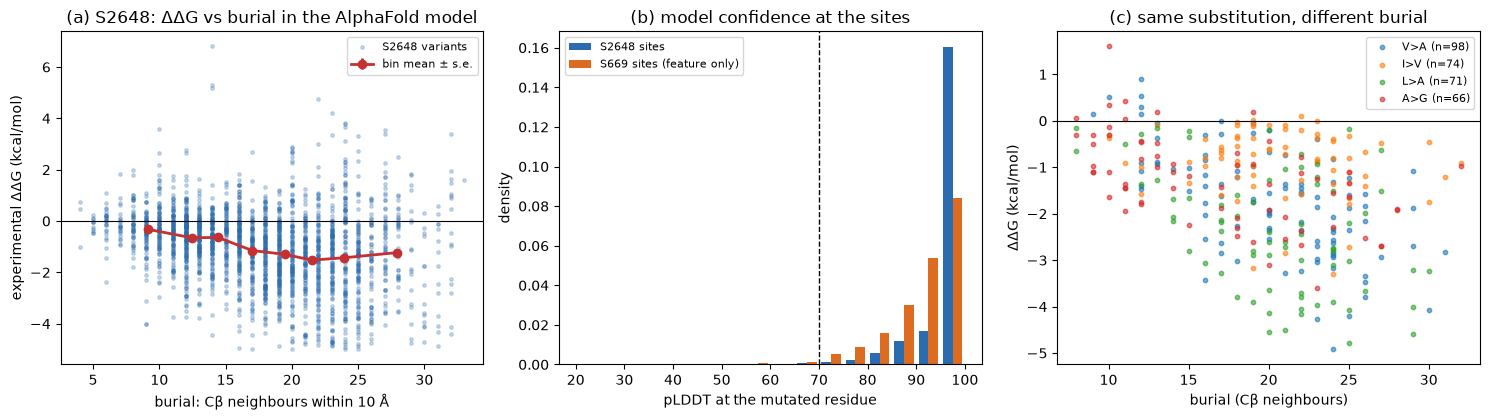

S2648 with AlphaFold features: 2296 of 2648 variants; Spearman ρ(burial, ΔΔG) = -0.28 (negative = buried sites destabilise more)
fraction of S2648 sites with pLDDT >= 70: 99.4% of those with a model


In [8]:
V = dp.sentinels_to_nan(variants)
train = V[V.dataset == "S2648"].reset_index(drop=True)
test = V[V.dataset == "S669"].reset_index(drop=True)
has_af_tr = train.plddt.notna()

t = train[has_af_tr & train.burial_cn10.notna()]
assert len(t) > 50, ("too few S2648 variants have AlphaFold features (SIFTS or AlphaFold DB unreachable during the "
                     "pipeline run?); re-run `python data_pipeline_ly.py`")
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ax[0].scatter(t.burial_cn10, t.ddg_kcal_mol, s=6, alpha=0.25, color="#2b6cb0", label="S2648 variants")
bins = np.quantile(t.burial_cn10, np.linspace(0, 1, 9))
mid = pd.cut(t.burial_cn10, np.unique(bins), include_lowest=True)
g = t.groupby(mid, observed=True).agg(cn=("burial_cn10", "mean"), ddg=("ddg_kcal_mol", "mean"), se=("ddg_kcal_mol", "sem"))
ax[0].errorbar(g.cn, g.ddg, yerr=g.se, color="#c53030", marker="o", lw=2, label="bin mean ± s.e.")
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set(xlabel=f"burial: Cβ neighbours within {dp.BURIAL_RADIUS_A:g} Å", ylabel="experimental ΔΔG (kcal/mol)",
          title="(a) S2648: ΔΔG vs burial in the AlphaFold model")
ax[0].legend(fontsize=8)

ax[1].hist([train.plddt.dropna(), test.plddt.dropna()], bins=np.arange(20, 101, 5), density=True,
           label=["S2648 sites", "S669 sites (feature only)"], color=["#2b6cb0", "#dd6b20"])
ax[1].axvline(70, color="k", ls="--", lw=1)
ax[1].set(xlabel="pLDDT at the mutated residue", ylabel="density", title="(b) model confidence at the sites")
ax[1].legend(fontsize=8)

t2 = train[has_af_tr].assign(pair=lambda d: d.wt + ">" + d.mt)
top = t2.pair.value_counts().index[:4]
for k, p in enumerate(top):
    d = t2[t2.pair == p]
    ax[2].scatter(d.burial_cn10, d.ddg_kcal_mol, s=10, alpha=0.6, label=f"{p} (n={len(d)})")
ax[2].axhline(0, color="k", lw=0.8)
ax[2].set(xlabel="burial (Cβ neighbours)", ylabel="ΔΔG (kcal/mol)",
          title="(c) same substitution, different burial")
ax[2].legend(fontsize=8)
fig.tight_layout(); plt.show()

rho = t[["burial_cn10", "ddg_kcal_mol"]].corr(method="spearman").iloc[0, 1]
print(f"S2648 with AlphaFold features: {int(has_af_tr.sum())} of {len(train)} variants; "
      f"Spearman ρ(burial, ΔΔG) = {rho:+.2f} (negative = buried sites destabilise more)")
print(f"fraction of S2648 sites with pLDDT >= 70: {(train.plddt >= 70).mean() / has_af_tr.mean():.1%} of those with a model")


## 5. First analysis: AF-ΔΔG compared with the Week 8 baseline

### 5a. The Week 8 baseline, rebuilt from the normalised data

The baseline is refitted from the pipeline's table with the ridge penalty frozen in Week 8 (`baseline/baseline_results_ly.json`). If the ingestion layer had changed any ΔΔG value, any mutation or the row order, the predictions below would differ from the frozen Week 8 predictions (`baseline/baseline_predictions_s669_ly.csv`). They must agree to machine precision.

In [9]:
frozen = json.loads((HERE / "baseline" / "baseline_results_ly.json").read_text())
frozen_pred = pd.read_csv(HERE / "baseline" / "baseline_predictions_s669_ly.csv")

X_tr_seq, y_tr = F.featurise(train.source_mutation), train.ddg_kcal_mol.to_numpy()
X_te_seq, y_te = F.featurise(test.source_mutation), test.ddg_kcal_mol.to_numpy()
groups_te = test.group.to_numpy()                       # 87 proteins -> clustered bootstrap

baseline = make_pipeline(StandardScaler(), Ridge(alpha=frozen["ridge_alpha"])).fit(X_tr_seq, y_tr)
pred_base = baseline.predict(X_te_seq)
pred_null = np.full_like(y_te, y_tr.mean())

assert (frozen_pred.mutation.to_numpy() == test.source_mutation.to_numpy()).all()
assert np.allclose(frozen_pred.ddg, y_te) and np.allclose(frozen_pred.pred_baseline, pred_base, atol=1e-9)
print(f"Week 8 baseline reproduced from the pipeline output: max |Δ| = "
      f"{np.abs(frozen_pred.pred_baseline - pred_base).max():.1e} kcal/mol over {len(test)} S669 variants; "
      f"RMSE = {S.rmse(y_te, pred_base):.3f} kcal/mol (Week 8: {frozen['baseline']['rmse_kcal_mol']:.3f})")


Week 8 baseline reproduced from the pipeline output: max |Δ| = 0.0e+00 kcal/mol over 669 S669 variants; RMSE = 1.538 kcal/mol (Week 8: 1.538)


### 5b. AF-ΔΔG: the AlphaFold-informed model

AF-ΔΔG is a gradient-boosted regressor (scikit-learn `HistGradientBoostingRegressor`) on the **same 10 sequence descriptors as the baseline plus 6 AlphaFold DB features** of the mutated site:

| feature | physical meaning |
|---|---|
| `burial_cn10` | packing / burial in the wild-type model (hydrophobic effect, cavity creation) |
| `plddt`, `plddt_window` | how far the model, and therefore the burial value, can be trusted |
| `rel_position` | position along the chain (termini are usually frayed) |
| `am_pathogenicity`, `am_position_mean` | AlphaMissense prior: evolutionary and structural intolerance of the site (human proteins only) |

Gradient boosting handles the missing values natively (NaN), so variants without AlphaMissense still use their structural features. Hyperparameters are chosen by 5-fold cross-validation on S2648 with **the same cluster-grouped folds as Week 8**. As a control I fit the **same model class on the sequence descriptors only** (`HGB, sequence only`). Any gain of AF-ΔΔG over that control comes from the structure, not from switching from ridge regression to boosting.

Following the evaluation protocol, S669 variants without AlphaFold data (no accession, no model, or an unmapped residue) receive the **baseline prediction**, so n = 669 always.

In [10]:
AF_FEATURES = ["plddt", "plddt_window", "burial_cn10", "rel_position", "am_pathogenicity", "am_position_mean"]
X_tr = pd.concat([X_tr_seq.reset_index(drop=True), train[AF_FEATURES]], axis=1)
X_te = pd.concat([X_te_seq.reset_index(drop=True), test[AF_FEATURES]], axis=1)

# the Week 8 folds: whole sequence clusters (CLID), largest first, into the lightest fold
sizes = train.groupby("group").size().sort_values(ascending=False, kind="mergesort")
fold_of, load = {}, np.zeros(5, dtype=int)
for clid, n in sizes.items():
    k = int(np.argmin(load)); fold_of[clid] = k; load[k] += n
cv = PredefinedSplit(train.group.map(fold_of).to_numpy())

def hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=300, l2_regularization=1.0, random_state=SEED, **kw)

grid = [dict(learning_rate=lr, max_leaf_nodes=leaves, min_samples_leaf=msl)
        for lr in (0.03, 0.1) for leaves in (7, 15) for msl in (20, 50)]
cv_rows = []
for name, X in [("HGB, sequence only", X_tr_seq), ("AF-ΔΔG (sequence + AlphaFold)", X_tr)]:
    for params in grid:
        p_cv = cross_val_predict(hgb(**params), X, y_tr, cv=cv)
        cv_rows.append({"model": name, **params, "CV RMSE (kcal/mol)": S.rmse(y_tr, p_cv)})
cv_table = pd.DataFrame(cv_rows)
best = cv_table.loc[cv_table.groupby("model")["CV RMSE (kcal/mol)"].idxmin()].set_index("model")
p_cv_ridge = cross_val_predict(make_pipeline(StandardScaler(), Ridge(alpha=frozen["ridge_alpha"])), X_tr_seq, y_tr, cv=cv)
print(f"grouped-CV RMSE on S2648: PhysChem-Ridge baseline {S.rmse(y_tr, p_cv_ridge):.3f} kcal/mol")
display(best)

params_af = {k: best.loc["AF-ΔΔG (sequence + AlphaFold)", k] for k in ("learning_rate", "max_leaf_nodes", "min_samples_leaf")}
params_seq = {k: best.loc["HGB, sequence only", k] for k in ("learning_rate", "max_leaf_nodes", "min_samples_leaf")}
params_af = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in params_af.items()}
params_seq = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in params_seq.items()}
af_model = hgb(**params_af).fit(X_tr, y_tr)          # frozen from here on
seq_model = hgb(**params_seq).fit(X_tr_seq, y_tr)


grouped-CV RMSE on S2648: PhysChem-Ridge baseline 1.357 kcal/mol


,learning_rate,max_leaf_nodes,min_samples_leaf,CV RMSE (kcal/mol)
model,,,,
AF-ΔΔG (sequence + AlphaFold),0.03,7,20,1.278
"HGB, sequence only",0.03,7,20,1.335


### 5c. Scoring on S669 (once)

Primary metric RMSE in kcal/mol, with 95 % confidence intervals from a bootstrap over **proteins** (2000 resamples), and the paired bootstrap of ΔRMSE against the baseline on identical resamples. The success rule of the protocol is RMSE ≤ RT ln 10 = 1.36 kcal/mol **and** a ΔRMSE confidence interval entirely below zero.

In [11]:
has_af_te = test.plddt.notna().to_numpy()
pred_af = np.where(has_af_te, af_model.predict(X_te), pred_base)      # protocol: baseline where AF data are missing
pred_seq = seq_model.predict(X_te_seq)
models = {"Null (S2648 mean)": pred_null, "PhysChem-Ridge baseline (Week 8)": pred_base,
          "HGB, sequence only (control)": pred_seq, "AF-ΔΔG (this week)": pred_af}

rows, cis = {}, {}
for name, p in models.items():
    sc = S.score(y_te, p)
    cis[name] = S.bootstrap_ci(y_te, p, groups_te, seed=SEED)
    rows[name] = {"RMSE (kcal/mol)": sc["rmse_kcal_mol"], "RMSE 95% CI": f"[{cis[name]['ci_low']:.2f}, {cis[name]['ci_high']:.2f}]",
                  "MAE (kcal/mol)": sc["mae_kcal_mol"], "Pearson r": sc["pearson_r"], "Spearman ρ": sc["spearman_rho"],
                  "RMSE / RT": sc["rmse_in_RT"], "n": sc["n"]}
results = pd.DataFrame(rows).T
display(results)

delta = S.paired_bootstrap_delta(y_te, pred_af, pred_base, groups_te, seed=SEED)
delta_ctrl = S.paired_bootstrap_delta(y_te, pred_af, pred_seq, groups_te, seed=SEED)
sub = has_af_te
delta_sub = S.paired_bootstrap_delta(y_te[sub], pred_af[sub], pred_base[sub], groups_te[sub], seed=SEED)
print(f"S669 variants with AlphaFold features: {int(sub.sum())} of {len(test)} "
      f"({len(test) - int(sub.sum())} use the baseline prediction)")
print(f"ΔRMSE (AF-ΔΔG − baseline), all 669:          {delta['delta']:+.3f} kcal/mol, 95% CI [{delta['ci_low']:+.3f}, {delta['ci_high']:+.3f}]")
print(f"ΔRMSE (AF-ΔΔG − baseline), with AF data:     {delta_sub['delta']:+.3f} kcal/mol, 95% CI [{delta_sub['ci_low']:+.3f}, {delta_sub['ci_high']:+.3f}]")
print(f"ΔRMSE (AF-ΔΔG − sequence-only HGB control):  {delta_ctrl['delta']:+.3f} kcal/mol, 95% CI [{delta_ctrl['ci_low']:+.3f}, {delta_ctrl['ci_high']:+.3f}]")
print(S.verdict(S.rmse(y_te, pred_af), delta["ci_high"]))


,RMSE (kcal/mol),RMSE 95% CI,MAE (kcal/mol),Pearson r,Spearman ρ,RMSE / RT,n
Null (S2648 mean),1.623,"[1.41, 1.89]",1.226,-0.0,NaN,2.739,669
PhysChem-Ridge baseline (Week 8),1.538,"[1.27, 1.87]",1.133,0.32,0.33,2.596,669
"HGB, sequence only (control)",1.559,"[1.28, 1.89]",1.123,0.316,0.35,2.631,669
AF-ΔΔG (this week),1.569,"[1.27, 1.92]",1.131,0.334,0.361,2.648,669


S669 variants with AlphaFold features: 620 of 669 (49 use the baseline prediction)
ΔRMSE (AF-ΔΔG − baseline), all 669:          +0.031 kcal/mol, 95% CI [-0.053, +0.099]
ΔRMSE (AF-ΔΔG − baseline), with AF data:     +0.033 kcal/mol, 95% CI [-0.060, +0.108]
ΔRMSE (AF-ΔΔG − sequence-only HGB control):  +0.010 kcal/mol, 95% CI [-0.108, +0.101]
RMSE = 1.569 kcal/mol vs threshold 1.36 kcal/mol (RT ln10 at 298.15 K): DOES NOT MEET the success threshold; improvement over baseline is NOT significant


In [12]:
# Per-variant view with the Meeting 1 harness (same tolerance rule as Week 8: |error| <= 1.36 kcal/mol + sign rule)
truth_items = [{"id": f"{r.protein}-{r.source_mutation}", "kind": "numeric", "value": float(r.ddg_kcal_mol),
                "unit": "kcal/mol", "regime": "typical" if -2 < r.ddg_kcal_mol <= 0.5 else "edge",
                "tolerance": {"abs": S.SUCCESS_RMSE_KCAL}} for r in test.itertuples()]

def harness_summary(pred):
    h = pd.DataFrame([H.score_item(i, {"value": float(v), "unit": "kcal/mol"}) for i, v in zip(truth_items, pred)])
    out = {"pass rate [all]": h.passed.mean()}
    for reg in ("typical", "edge"):
        out[f"pass rate [{reg}] (n={int((h.regime == reg).sum())})"] = h[h.regime == reg].passed.mean()
    out["worst |error| (kcal/mol)"] = h.error.max()
    out["worst item"] = h.loc[h.error.idxmax(), "id"]
    return out

harness = pd.DataFrame({name: harness_summary(p) for name, p in models.items()})
display(harness)


,Null (S2648 mean),PhysChem-Ridge baseline (Week 8),"HGB, sequence only (control)",AF-ΔΔG (this week)
pass rate [all],0.671,0.713,0.707,0.691
pass rate [typical] (n=428),0.949,0.921,0.888,0.86
pass rate [edge] (n=241),0.178,0.344,0.386,0.39
worst |error| (kcal/mol),7.917,6.789,6.725,6.584
worst item,P54178-W55A,P54178-W55A,P54178-W55A,O73951-E53A


### 5d. Comparison plot: AF-ΔΔG vs the Week 8 baseline

* **(a)** Parity plot of all 669 S669 variants for both models. The grey band is the per-variant tolerance ±RT ln 10.
* **(b)** Ten individual variants: the two ΔΔG items of my Meeting 1 ground-truth file, plus eight variants drawn with a fixed seed (two from each experimental-ΔΔG range, among variants that have AlphaFold features). The table below the figure lists the same ten points.
* **(c)** RMSE with protein-bootstrap 95 % confidence intervals against the success threshold.
* **(d)** RMSE by burial class of the mutated residue. The class edges are the terciles of `burial_cn10` in the training set.

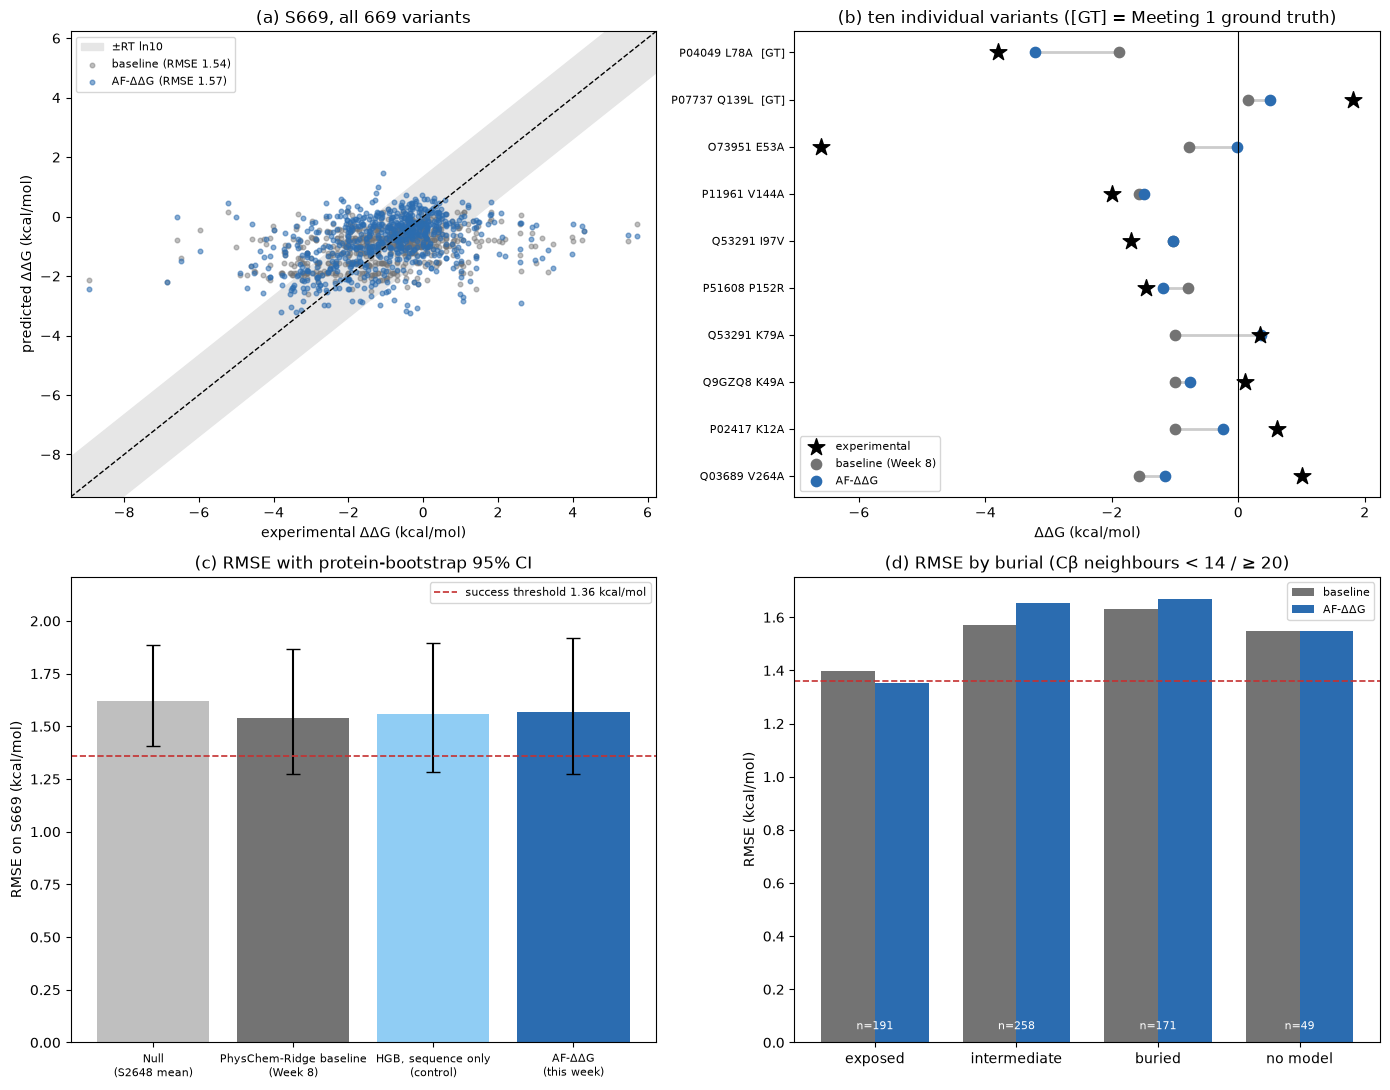

,label,experimental,baseline,AF-ΔΔG,plddt,burial_cn10,am_pathogenicity,|err| baseline,|err| AF-ΔΔG
0,P04049 L78A,-3.803,-1.886,-3.211,89.75,23.0,0.971,1.917,0.592
1,P07737 Q139L,1.820,0.152,0.501,85.50,8.0,0.477,1.668,1.319
2,O73951 E53A,-6.597,-0.784,-0.013,98.62,17.0,NaN,5.813,6.584
3,P11961 V144A,-2.000,-1.567,-1.491,84.00,17.0,NaN,0.433,0.509
4,Q53291 I97V,-1.690,-1.033,-1.026,86.94,24.0,NaN,0.657,0.664
5,P51608 P152R,-1.460,-0.789,-1.191,86.75,15.0,0.999,0.671,0.269
6,Q53291 K79A,0.350,-1.005,0.357,74.12,8.0,NaN,1.355,0.007
7,Q9GZQ8 K49A,0.100,-1.005,-0.757,93.38,8.0,0.996,1.105,0.857
8,P02417 K12A,0.610,-1.005,-0.235,90.00,16.0,NaN,1.615,0.845
9,Q03689 V264A,1.000,-1.567,-1.165,91.19,16.0,NaN,2.567,2.165


In [13]:
rng = np.random.default_rng(SEED)
gt = json.loads((HERE / "ground_truth_ly.json").read_text())
picked = [int(test.index[(test.protein == i["s669_protein"]) & (test.source_mutation == i["s669_mutation"])][0])
          for i in gt["items"] if "s669_protein" in i]
bin_edges = [-np.inf, -2, -0.5, 0.5, np.inf]
ddg_bin = pd.cut(test.ddg_kcal_mol, bin_edges, labels=False)
for b in range(4):
    pool = np.flatnonzero((ddg_bin == b).to_numpy() & has_af_te)
    pool = np.setdiff1d(pool, picked)
    picked += sorted(rng.choice(pool, size=min(2, len(pool)), replace=False).tolist())
sel = test.loc[picked].assign(baseline=pred_base[picked], af_ddg=pred_af[picked])
sel["label"] = sel.uniprot_accession.where(sel.uniprot_accession != dp.SENTINEL_STR, sel.protein) + " " + sel.source_mutation

cn_edges = np.nanquantile(train.burial_cn10, [1 / 3, 2 / 3])
def burial_class(cn):
    return np.where(np.isnan(cn), "no model", np.where(cn < cn_edges[0], "exposed", np.where(cn < cn_edges[1], "intermediate", "buried")))
bclass = burial_class(test.burial_cn10.to_numpy())

fig, ax = plt.subplots(2, 2, figsize=(14, 11))
lim = (min(y_te.min(), pred_af.min(), pred_base.min()) - 0.5, max(y_te.max(), pred_af.max(), pred_base.max()) + 0.5)
a = ax[0, 0]
a.fill_between(lim, np.array(lim) - S.RT_LN10, np.array(lim) + S.RT_LN10, color="0.9", zorder=0, label="±RT ln10")
a.plot(lim, lim, "k--", lw=1)
a.scatter(y_te, pred_base, s=11, alpha=0.45, color="0.45", label=f"baseline (RMSE {S.rmse(y_te, pred_base):.2f})")
a.scatter(y_te, pred_af, s=11, alpha=0.55, color="#2b6cb0", label=f"AF-ΔΔG (RMSE {S.rmse(y_te, pred_af):.2f})")
a.set(xlim=lim, ylim=lim, xlabel="experimental ΔΔG (kcal/mol)", ylabel="predicted ΔΔG (kcal/mol)",
      title="(a) S669, all 669 variants")
a.legend(fontsize=8, loc="upper left")

a = ax[0, 1]
ypos = np.arange(len(sel))[::-1]
for yy, (_, r) in zip(ypos, sel.iterrows()):
    a.plot([r.baseline, r.af_ddg], [yy, yy], color="0.8", lw=2, zorder=0)
a.scatter(sel.ddg_kcal_mol, ypos, marker="*", s=160, color="k", label="experimental", zorder=3)
a.scatter(sel.baseline, ypos, s=55, color="0.45", label="baseline (Week 8)", zorder=2)
a.scatter(sel.af_ddg, ypos, s=55, color="#2b6cb0", label="AF-ΔΔG", zorder=2)
a.axvline(0, color="k", lw=0.8)
a.set_yticks(ypos, [f"{l}{'  [GT]' if k < 2 else ''}" for k, l in enumerate(sel.label)], fontsize=8)
a.set(xlabel="ΔΔG (kcal/mol)", title="(b) ten individual variants ([GT] = Meeting 1 ground truth)")
a.legend(fontsize=8, loc="lower left")

a = ax[1, 0]
names = list(models)
vals = [S.rmse(y_te, models[n]) for n in names]
err = np.array([[v - cis[n]["ci_low"], cis[n]["ci_high"] - v] for n, v in zip(names, vals)]).T
colors = ["0.75", "0.45", "#90cdf4", "#2b6cb0"]
a.bar(range(len(names)), vals, yerr=err, color=colors, capsize=5)
a.axhline(S.SUCCESS_RMSE_KCAL, color="#c53030", ls="--", lw=1.2, label="success threshold 1.36 kcal/mol")
a.set_xticks(range(len(names)), [n.replace(" (", "\n(") for n in names], fontsize=8)
a.set(ylabel="RMSE on S669 (kcal/mol)", title="(c) RMSE with protein-bootstrap 95% CI")
a.set_ylim(0, max(err[1] + vals) * 1.15)
a.legend(fontsize=8)

a = ax[1, 1]
classes = ["exposed", "intermediate", "buried", "no model"]
w = 0.38
for j, (name, p, col) in enumerate([("baseline", pred_base, "0.45"), ("AF-ΔΔG", pred_af, "#2b6cb0")]):
    r = [S.rmse(y_te[bclass == c], p[bclass == c]) if (bclass == c).any() else np.nan for c in classes]
    a.bar(np.arange(4) + (j - 0.5) * w, r, width=w, color=col, label=name)
for k, c in enumerate(classes):
    a.text(k, 0.05, f"n={int((bclass == c).sum())}", ha="center", fontsize=8, color="w")
a.axhline(S.SUCCESS_RMSE_KCAL, color="#c53030", ls="--", lw=1.2)
a.set_xticks(range(4), classes)
a.set(ylabel="RMSE (kcal/mol)", title=f"(d) RMSE by burial (Cβ neighbours < {cn_edges[0]:.0f} / ≥ {cn_edges[1]:.0f})")
a.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / "first_result_vs_baseline_ly.png", dpi=150)
plt.show()

display(sel[["label", "ddg_kcal_mol", "baseline", "af_ddg", "plddt", "burial_cn10", "am_pathogenicity"]]
        .assign(**{"|err| baseline": lambda d: (d.baseline - d.ddg_kcal_mol).abs(),
                   "|err| AF-ΔΔG": lambda d: (d.af_ddg - d.ddg_kcal_mol).abs()})
        .rename(columns={"ddg_kcal_mol": "experimental", "af_ddg": "AF-ΔΔG"}).reset_index(drop=True))


In [14]:
# Secondary metric of the protocol: RMSE per pLDDT band (only variants with AlphaFold data)
band = pd.cut(test.plddt, [0, 50, 70, 90, 100.01], labels=["very low (<50)", "low (50-70)", "confident (70-90)", "very high (>90)"],
              right=False)
by_band = pd.DataFrame({
    "n": test.groupby(band, observed=False).size(),
    "baseline RMSE": [S.rmse(y_te[(band == b).to_numpy()], pred_base[(band == b).to_numpy()]) if (band == b).any() else np.nan
                      for b in band.cat.categories],
    "AF-ΔΔG RMSE": [S.rmse(y_te[(band == b).to_numpy()], pred_af[(band == b).to_numpy()]) if (band == b).any() else np.nan
                    for b in band.cat.categories]}, index=band.cat.categories)
by_burial = pd.DataFrame({c: {"n": int((bclass == c).sum()),
                              "baseline RMSE": S.rmse(y_te[bclass == c], pred_base[bclass == c]) if (bclass == c).any() else np.nan,
                              "AF-ΔΔG RMSE": S.rmse(y_te[bclass == c], pred_af[bclass == c]) if (bclass == c).any() else np.nan}
                          for c in classes}).T
display(by_band, by_burial)


,n,baseline RMSE,AF-ΔΔG RMSE
very low (<50),0,NaN,NaN
low (50-70),6,0.906,1.064
confident (70-90),187,1.230,1.280
very high (>90),427,1.661,1.687


,n,baseline RMSE,AF-ΔΔG RMSE
exposed,191.0,1.397,1.351
intermediate,258.0,1.571,1.652
buried,171.0,1.633,1.669
no model,49.0,1.548,1.548


In [15]:
# Persist the first result next to the Week 8 baseline files
out = {
    "model": "AF-ΔΔG: HistGradientBoostingRegressor on 10 sequence descriptors + 6 AlphaFold DB features",
    "features": list(X_tr.columns), "hyperparameters": params_af, "seed": SEED,
    "train_set": "S2648 (normalised by data_pipeline_ly.py)", "test_set": "S669 (669 direct variants)",
    "pipeline_content_sha256": prov["outputs"]["variants"]["content_sha256"],
    "n_test_with_alphafold_features": int(has_af_te.sum()),
    "scores": {n: S.score(y_te, p) for n, p in models.items()},
    "rmse_ci95": cis,
    "delta_rmse_af_minus_baseline": delta, "delta_rmse_af_minus_baseline_af_subset": delta_sub,
    "delta_rmse_af_minus_sequence_control": delta_ctrl,
    "verdict": S.verdict(S.rmse(y_te, pred_af), delta["ci_high"]),
    "rmse_by_burial_class": by_burial.to_dict(orient="index"),
    "rmse_by_plddt_band": by_band.to_dict(orient="index"),
    "harness": harness.to_dict(),
}
(RESULTS / "af_ddg_results_ly.json").write_text(json.dumps(out, indent=2, default=float))
test.assign(pred_baseline=pred_base, pred_af_ddg=pred_af, pred_hgb_sequence=pred_seq, burial_class=bclass)[
    ["variant_id", "protein", "uniprot_accession", "source_mutation", "ddg_kcal_mol", "plddt", "burial_cn10",
     "burial_class", "pred_baseline", "pred_hgb_sequence", "pred_af_ddg"]].to_csv(RESULTS / "af_ddg_predictions_s669_ly.csv", index=False)
print("saved:", *sorted(p.name for p in RESULTS.iterdir()))


saved: af_ddg_predictions_s669_ly.csv af_ddg_results_ly.json first_result_vs_baseline_ly.png


## 6. Results and discussion

Section 6a summarises the numbers computed above (generated from the outputs). Section 6b is my discussion of what they mean. Cell 6c checks every number quoted in 6b against the computed results, so the text cannot drift from the data if the notebook is re-run. 6d and 6e list the limitations and the plan for Weeks 10–13.

### 6a. Summary computed from the outputs

In [16]:
r_af, r_base, r_seq = S.rmse(y_te, pred_af), S.rmse(y_te, pred_base), S.rmse(y_te, pred_seq)
cv_af = best.loc["AF-ΔΔG (sequence + AlphaFold)", "CV RMSE (kcal/mol)"]
cv_seq = best.loc["HGB, sequence only", "CV RMSE (kcal/mol)"]
cv_ridge = S.rmse(y_tr, p_cv_ridge)

def judge(d, what):
    if d["ci_high"] < 0:
        return f"**significantly better** than {what}"
    if d["delta"] < 0:
        return f"better than {what} on average, but **not significantly** (the CI includes 0)"
    return f"**not better** than {what}"

bur = (by_burial["AF-ΔΔG RMSE"] - by_burial["baseline RMSE"]).drop("no model").dropna()
if (bur < 0).any():
    burial_txt = (f"By burial class, the error drops most for **{bur.idxmin()}** residues "
                  f"({bur.min():+.2f} kcal/mol relative to the baseline) and rises most for **{bur.idxmax()}** "
                  f"residues ({bur.max():+.2f} kcal/mol).")
else:
    burial_txt = "No burial class is predicted better than by the baseline."
bands = by_band.dropna(subset=["baseline RMSE"])
bands = bands[bands.n >= 20]
band_txt = ""
if len(bands) >= 2:
    hi, lo = bands["baseline RMSE"].idxmax(), bands["baseline RMSE"].idxmin()
    band_txt = (f" The largest errors are in the **{hi}** pLDDT band (baseline RMSE {bands.loc[hi, 'baseline RMSE']:.2f}, "
                f"AF-ΔΔG {bands.loc[hi, 'AF-ΔΔG RMSE']:.2f} kcal/mol, n = {int(bands.loc[hi, 'n'])}), the smallest in the "
                f"**{lo}** band ({bands.loc[lo, 'baseline RMSE']:.2f} / {bands.loc[lo, 'AF-ΔΔG RMSE']:.2f} kcal/mol, "
                f"n = {int(bands.loc[lo, 'n'])})" + (", so the remaining error is **not** caused by unreliable, low-confidence "
                "coordinates." if "very high" in str(hi) or "confident" in str(hi) else "."))
cv_gain = cv_af - cv_seq
transfer = (r_af - r_seq)
gap_txt = (f"**Training set vs test set.** In cluster-grouped cross-validation on S2648 the AlphaFold features lower the "
           f"error from {cv_seq:.3f} (same model, sequence only) to **{cv_af:.3f} kcal/mol** ({cv_gain:+.3f}; PhysChem-Ridge "
           f"{cv_ridge:.3f}), and burial correlates with ΔΔG as expected (Spearman ρ = {rho:+.2f}: buried sites destabilise more). ")
if cv_gain < 0 and transfer >= 0:
    gap_txt += ("On S669 this gain **does not transfer** "
                f"({r_af:.3f} vs {r_seq:.3f} kcal/mol). S669 proteins share < 25 % sequence identity with S2648, so the "
                "most likely reading is that the tree model has learned protein-family-specific combinations of burial and "
                "substitution type rather than a transferable physical rule; this generalisation gap, not the data, is "
                "the main target for Weeks 10–13.")
elif cv_gain < 0:
    gap_txt += f"On S669 the structural features also help ({transfer:+.3f} kcal/mol against the control)."
else:
    gap_txt += "Even within the training distribution the AlphaFold features do not lower the error."
lines = [
    f"**Headline.** On the 669 S669 variants AF-ΔΔG reaches **RMSE = {r_af:.2f} kcal/mol** "
    f"(95 % CI {cis['AF-ΔΔG (this week)']['ci_low']:.2f}–{cis['AF-ΔΔG (this week)']['ci_high']:.2f}), against "
    f"**{r_base:.2f} kcal/mol** for the Week 8 baseline. ΔRMSE = {delta['delta']:+.2f} kcal/mol "
    f"(paired 95 % CI [{delta['ci_low']:+.2f}, {delta['ci_high']:+.2f}]), so AF-ΔΔG is {judge(delta, 'the baseline')}.",
    f"**Success rule.** {S.verdict(r_af, delta['ci_high'])}. In units of thermal energy the error is "
    f"{r_af / S.RT:.1f} RT at 298 K, i.e. the folding equilibrium constant of a typical variant is predicted to within a "
    f"factor of about {np.exp(r_af / S.RT):.0f}.",
    f"**Structure or model class?** The same boosting model without AlphaFold features scores {r_seq:.2f} kcal/mol on S669. "
    f"Against this control, AF-ΔΔG is {judge(delta_ctrl, 'the control')} (ΔRMSE = {delta_ctrl['delta']:+.2f} kcal/mol, "
    f"CI [{delta_ctrl['ci_low']:+.2f}, {delta_ctrl['ci_high']:+.2f}]). This is the cleanest measure of what the "
    f"AlphaFold features themselves add. {burial_txt}",
    gap_txt,
    f"**Where the errors are.** Per variant (Meeting 1 harness), AF-ΔΔG passes {harness.loc['pass rate [all]', 'AF-ΔΔG (this week)']:.0%} "
    f"of all variants and {harness.filter(like='edge', axis=0).iloc[0]['AF-ΔΔG (this week)']:.0%} of the edge variants "
    f"(baseline: {harness.loc['pass rate [all]', 'PhysChem-Ridge baseline (Week 8)']:.0%} and "
    f"{harness.filter(like='edge', axis=0).iloc[0]['PhysChem-Ridge baseline (Week 8)']:.0%})." + band_txt,
    f"**Coverage.** {int(has_af_te.sum())} of 669 test variants have AlphaFold features; the other "
    f"{669 - int(has_af_te.sum())} fall back to the baseline prediction, which dilutes any difference. On the subset "
    f"with features, ΔRMSE = {delta_sub['delta']:+.2f} kcal/mol (CI [{delta_sub['ci_low']:+.2f}, {delta_sub['ci_high']:+.2f}]). "
    f"AlphaMissense exists only for human proteins: {int(test.am_pathogenicity.notna().sum())} test and "
    f"{int(train.am_pathogenicity.notna().sum())} training variants have it.",
]
display(Markdown("\n\n".join(lines)))


**Headline.** On the 669 S669 variants AF-ΔΔG reaches **RMSE = 1.57 kcal/mol** (95 % CI 1.27–1.92), against **1.54 kcal/mol** for the Week 8 baseline. ΔRMSE = +0.03 kcal/mol (paired 95 % CI [-0.05, +0.10]), so AF-ΔΔG is **not better** than the baseline.

**Success rule.** RMSE = 1.569 kcal/mol vs threshold 1.36 kcal/mol (RT ln10 at 298.15 K): DOES NOT MEET the success threshold; improvement over baseline is NOT significant. In units of thermal energy the error is 2.6 RT at 298 K, i.e. the folding equilibrium constant of a typical variant is predicted to within a factor of about 14.

**Structure or model class?** The same boosting model without AlphaFold features scores 1.56 kcal/mol on S669. Against this control, AF-ΔΔG is **not better** than the control (ΔRMSE = +0.01 kcal/mol, CI [-0.11, +0.10]). This is the cleanest measure of what the AlphaFold features themselves add. By burial class, the error drops most for **exposed** residues (-0.05 kcal/mol relative to the baseline) and rises most for **intermediate** residues (+0.08 kcal/mol).

**Training set vs test set.** In cluster-grouped cross-validation on S2648 the AlphaFold features lower the error from 1.335 (same model, sequence only) to **1.278 kcal/mol** (-0.056; PhysChem-Ridge 1.357), and burial correlates with ΔΔG as expected (Spearman ρ = -0.28: buried sites destabilise more). On S669 this gain **does not transfer** (1.569 vs 1.559 kcal/mol). S669 proteins share < 25 % sequence identity with S2648, so the most likely reading is that the tree model has learned protein-family-specific combinations of burial and substitution type rather than a transferable physical rule; this generalisation gap, not the data, is the main target for Weeks 10–13.

**Where the errors are.** Per variant (Meeting 1 harness), AF-ΔΔG passes 69% of all variants and 39% of the edge variants (baseline: 71% and 34%). The largest errors are in the **very high (>90)** pLDDT band (baseline RMSE 1.66, AF-ΔΔG 1.69 kcal/mol, n = 427), the smallest in the **confident (70-90)** band (1.23 / 1.28 kcal/mol, n = 187), so the remaining error is **not** caused by unreliable, low-confidence coordinates.

**Coverage.** 620 of 669 test variants have AlphaFold features; the other 49 fall back to the baseline prediction, which dilutes any difference. On the subset with features, ΔRMSE = +0.03 kcal/mol (CI [-0.06, +0.11]). AlphaMissense exists only for human proteins: 190 test and 454 training variants have it.

### 6b. Discussion

**What the pipeline delivered.** The ingestion layer turned two experimental datasets and four web services into a single table of 3317 variants in UniProt numbering. 620 of the 669 S669 test variants (93 %) and 2296 of the 2648 S2648 training variants (87 %) now carry AlphaFold features. Every gap is explained in `provenance_ly.json` and `missing_fields_ly.csv`:

- 13 UniProt accessions have no AlphaFold DB model. Among them are T4 lysozyme (P00720), a phage protein, and titin (Q8WZ42), which is too long for a single model.
- 3 of the 132 PDB chains in S2648 have no SIFTS mapping to UniProt.
- AlphaMissense exists only for human proteins, so only 190 test and 454 training variants have it.

The Week 8 baseline rebuilt from this table reproduces the frozen Week 8 predictions to machine precision, so the new layer changed none of the inputs the baseline sees. A complete re-download (`--fresh`) reproduced the table exactly (identical content hash).

**First result.** AF-ΔΔG reaches RMSE = 1.57 kcal/mol on S669 (95 % CI 1.27–1.92), against 1.54 kcal/mol for the Week 8 baseline: ΔRMSE = +0.03 kcal/mol, paired 95 % CI [−0.05, +0.10]. The AlphaFold-informed model is therefore **not better** than the baseline, and neither model meets the success threshold RT ln 10 = 1.36 kcal/mol.

- **Correlation.** It improves slightly: Pearson r 0.33 vs 0.32, Spearman ρ 0.36 vs 0.33.
- **Per variant (Meeting 1 harness).** AF-ΔΔG passes more of the strongly destabilising or stabilising *edge* variants (39 % vs 34 %) but fewer of the *typical* ones (86 % vs 92 %). The AlphaFold features spread the predictions out: that helps in the tails and costs in the crowded middle of the distribution.

The ten-variant close-up in panel (b) shows both sides:

- For my Meeting 1 ground-truth item **RAF1 L78A** (experimental −3.80 kcal/mol), AF-ΔΔG predicts −3.21 kcal/mol where the baseline predicted −1.89. The leucine sits in a confidently modelled region (pLDDT 90) and AlphaMissense rates the substitution as very likely damaging (0.97). This is exactly the kind of buried, intolerant site the structural features were meant to catch.
- For **O73951 E53A** (−6.60 kcal/mol) both models are far off (−0.78 and −0.01 kcal/mol). No substitution descriptor or burial count predicts a loss of more than 6 kcal/mol from an E→A mutation, which presumably removes a key salt bridge or hydrogen bond.

**The physics is visible in the training data, but it does not transfer yet.** Within S2648 the structural signal is real. Burial anti-correlates with ΔΔG (Spearman ρ = −0.28): the more Cβ neighbours a site has, the more destabilising its mutations, as the hydrophobic effect and cavity creation predict. Adding the AlphaFold features lowers the cluster-grouped cross-validation error from 1.335 to 1.278 kcal/mol.

On S669, however, the same features change the error by only +0.01 kcal/mol relative to the identical model without them (CI [−0.11, +0.10]). S669 was built to share less than 25 % sequence identity with S2648, so this is a genuine out-of-distribution test. My reading is that the boosted trees, which learn from only 113 sequence clusters, fit protein-family-specific combinations of burial and substitution type. They have not learned a transferable physical rule such as "losing side-chain volume costs free energy in proportion to burial".

**Where the remaining error is — not where I expected.**

- **By pLDDT band.** The largest errors are in the *very high* confidence band (pLDDT > 90: RMSE 1.66 kcal/mol for the baseline and 1.69 for AF-ΔΔG, n = 427), not in poorly modelled regions; only 6 test sites have pLDDT < 70. Unreliable coordinates are therefore not the problem. The hard variants are mutations in well-folded cores with large |ΔΔG|.
- **By burial class.** AF-ΔΔG helps for *exposed* residues (1.35 vs 1.40 kcal/mol), the only class in which it falls below the 1.36 kcal/mol threshold. It is worse for *intermediate* (1.65 vs 1.57) and *buried* (1.67 vs 1.63) residues, precisely where burial should matter most.

This points at the burial feature itself. A raw count of Cβ atoms within 10 Å does not tell a buried hydrophobic site from a buried polar or charged one, nor a large side chain from a small one. Nor can a static wild-type structure see how the mutant relaxes or what interactions it gains.

**Answer to the project question, for now.** At this first milestone, the AlphaFold structure of the wild-type protein does **not** give a measurable improvement in predicting ΔΔG for proteins unrelated to the training set. The structure clearly carries physically meaningful information: the burial–ΔΔG correlation, the cross-validation gain, and the better edge-variant pass rate all show it. The model does not yet use that information in a transferable way. The pipeline built this week makes this failure mode measurable and exactly reproducible, which is what the next weeks need.

In [17]:
# 6c. Check: every number quoted in 6b must match the computed results (to the precision quoted)
h_af, h_base = harness["AF-ΔΔG (this week)"], harness["PhysChem-Ridge baseline (Week 8)"]
edge_row = [k for k in harness.index if "edge" in k][0]
typ_row = [k for k in harness.index if "typical" in k][0]
sel_by = sel.set_index("label")
quoted = {  # name: (value quoted in the text, computed value, rounding decimals)
    "rows in the table": (3317, len(variants), 0),
    "S669 variants with AF features": (620, int(has_af_te.sum()), 0),
    "S2648 variants with AF features": (2296, int(train.plddt.notna().sum()), 0),
    "accessions without AF model": (13, len(next(d for d in prov["datasets"] if d["name"] == "AlphaFold DB prediction API")["accessions_without_model"]), 0),
    "PDB chains without SIFTS mapping": (3, int(variants[variants.dataset == "S2648"].groupby("protein").uniprot_accession.first().eq(dp.SENTINEL_STR).sum()), 0),
    "test variants with AlphaMissense": (190, int(test.am_pathogenicity.notna().sum()), 0),
    "training variants with AlphaMissense": (454, int(train.am_pathogenicity.notna().sum()), 0),
    "AF-ΔΔG RMSE": (1.57, r_af, 2), "baseline RMSE": (1.54, r_base, 2),
    "AF-ΔΔG RMSE CI low": (1.27, cis["AF-ΔΔG (this week)"]["ci_low"], 2),
    "AF-ΔΔG RMSE CI high": (1.92, cis["AF-ΔΔG (this week)"]["ci_high"], 2),
    "ΔRMSE vs baseline": (0.03, delta["delta"], 2), "ΔRMSE CI low": (-0.05, delta["ci_low"], 2),
    "ΔRMSE CI high": (0.10, delta["ci_high"], 2),
    "Pearson AF-ΔΔG": (0.33, S.pearson(y_te, pred_af), 2), "Pearson baseline": (0.32, S.pearson(y_te, pred_base), 2),
    "Spearman AF-ΔΔG": (0.36, S.spearman(y_te, pred_af), 2), "Spearman baseline": (0.33, S.spearman(y_te, pred_base), 2),
    "edge pass AF-ΔΔG (%)": (39, 100 * h_af[edge_row], 0), "edge pass baseline (%)": (34, 100 * h_base[edge_row], 0),
    "typical pass AF-ΔΔG (%)": (86, 100 * h_af[typ_row], 0), "typical pass baseline (%)": (92, 100 * h_base[typ_row], 0),
    "L78A AF-ΔΔG": (-3.21, sel_by.loc["P04049 L78A", "af_ddg"], 2), "L78A baseline": (-1.89, sel_by.loc["P04049 L78A", "baseline"], 2),
    "L78A pLDDT": (90, sel_by.loc["P04049 L78A", "plddt"], 0), "L78A AlphaMissense": (0.97, sel_by.loc["P04049 L78A", "am_pathogenicity"], 2),
    "E53A experimental": (-6.60, sel_by.loc["O73951 E53A", "ddg_kcal_mol"], 2),
    "E53A baseline": (-0.78, sel_by.loc["O73951 E53A", "baseline"], 2), "E53A AF-ΔΔG": (-0.01, sel_by.loc["O73951 E53A", "af_ddg"], 2),
    "burial ρ (S2648)": (-0.28, rho, 2), "CV RMSE sequence-only HGB": (1.335, cv_seq, 3), "CV RMSE AF-ΔΔG": (1.278, cv_af, 3),
    "ΔRMSE vs control": (0.01, delta_ctrl["delta"], 2), "control CI low": (-0.11, delta_ctrl["ci_low"], 2),
    "control CI high": (0.10, delta_ctrl["ci_high"], 2),
    "S2648 sequence clusters": (113, train.group.nunique(), 0),
    "very-high band n": (427, int(by_band.loc["very high (>90)", "n"]), 0),
    "very-high band RMSE baseline": (1.66, by_band.loc["very high (>90)", "baseline RMSE"], 2),
    "very-high band RMSE AF-ΔΔG": (1.69, by_band.loc["very high (>90)", "AF-ΔΔG RMSE"], 2),
    "test sites with pLDDT < 70": (6, int((test.plddt < 70).sum()), 0),
    "exposed RMSE AF-ΔΔG": (1.35, by_burial.loc["exposed", "AF-ΔΔG RMSE"], 2), "exposed RMSE baseline": (1.40, by_burial.loc["exposed", "baseline RMSE"], 2),
    "intermediate RMSE AF-ΔΔG": (1.65, by_burial.loc["intermediate", "AF-ΔΔG RMSE"], 2), "intermediate RMSE baseline": (1.57, by_burial.loc["intermediate", "baseline RMSE"], 2),
    "buried RMSE AF-ΔΔG": (1.67, by_burial.loc["buried", "AF-ΔΔG RMSE"], 2), "buried RMSE baseline": (1.63, by_burial.loc["buried", "baseline RMSE"], 2),
}
check = pd.DataFrame([{"quantity": k, "quoted in 6b": q, "computed": c, "matches": round(float(c), d) == round(float(q), d)}
                      for k, (q, c, d) in quoted.items()])
bad = check[~check.matches]
print(f"{int(check.matches.sum())} of {len(check)} numbers quoted in 6b match the computed results.")
if len(bad):
    display(bad)
    raise AssertionError("Some numbers quoted in 6b no longer match the outputs; update the text of 6b.")


46 of 46 numbers quoted in 6b match the computed results.


### 6d. Limitations

- **A single static structure.** Burial and pLDDT describe the wild-type AlphaFold model only. They say nothing about how the mutant relaxes, about the unfolded state, or about interactions created by the new side chain, and the stabilising tail is where this shows.
- **A deliberately small first model.** 8 hyperparameter settings were chosen on S2648 only, and S669 was scored once with each frozen model, as the protocol requires; nothing was tuned on the test set.
- **Wide confidence intervals.** The bootstrap over 87 S669 proteins gives intervals of about ±0.3 kcal/mol on the RMSE. Differences of a few hundredths of a kcal/mol are not resolvable, so "not better" means *no detectable improvement*, not *worse*.
- **Sparse AlphaMissense.** It covers human proteins only (454 training variants), so the model can barely learn from it.

### 6e. Next steps (Weeks 10–13)

1. **Physics-shaped, transferable features.** Add relative solvent accessibility normalised by side-chain size, a pLDDT-weighted contact count, and the products burial × Δhydropathy and burial × Δvolume, which encode the hydrophobic effect and cavity creation directly. Add monotonic constraints so that more burial can only make a volume loss more destabilising. Success criterion: the cross-validation gain on S2648 must now carry over to S669.
2. **Thermodynamic consistency.** Train on the reverse variants as well (ΔΔG(B→A) = −ΔΔG(A→B)) and report the antisymmetry check for AF-ΔΔG, as for the baseline in Week 8.
3. **Agent integration.** Expose the pipeline's per-variant features as a tool of my Assignment 7 MCP server, so the Meeting 1 harness can score the LLM agent on the two ΔΔG ground-truth items it cannot answer today.
4. **Peer review (Week 11).** The reviewer can re-create every number in this notebook with `bash run_all.sh --fresh`; cell 6c will flag any number that changes.